## 1. Import Library

In [18]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

%matplotlib inline

## 2. Membaca Citra
Citra dibaca dengan OpenCV (format BGR) lalu diubah ke RGB. Ubah `PATH_GAMBAR` sesuai lokasi file.

Ukuran citra : 533 x 800 piksel
Jumlah piksel: 426400
Dimensi array: (800, 533, 3) | tipe data: uint8


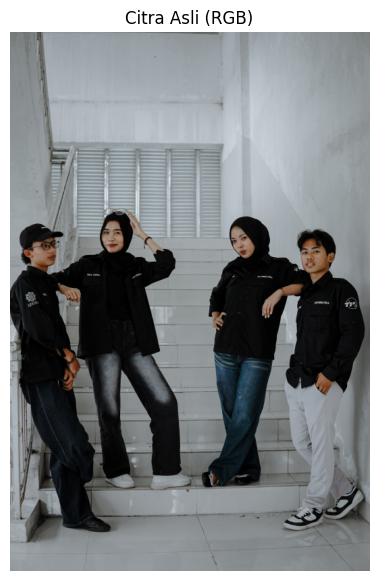

In [30]:
PATH_GAMBAR = "DSC00252.jpg"

bgr = cv2.imread(PATH_GAMBAR)
if bgr is None:
    raise FileNotFoundError(f"Gambar tidak ditemukan: {PATH_GAMBAR}")
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

# Perkecil agar proses lebih ringan
h, w = rgb.shape[:2]
skala = 800 / max(h, w)
if skala < 1:
    rgb = cv2.resize(rgb, (int(w * skala), int(h * skala)), interpolation=cv2.INTER_AREA)

print("Ukuran citra :", rgb.shape[1], "x", rgb.shape[0], "piksel")
print("Jumlah piksel:", rgb.shape[0] * rgb.shape[1])
print("Dimensi array:", rgb.shape, "| tipe data:", rgb.dtype)

plt.figure(figsize=(5, 7))
plt.imshow(rgb)
plt.title("Citra Asli (RGB)")
plt.axis("off")
plt.show()

## 3. Fungsi Operasi Titik

In [20]:
def clip_uint8(arr):
    """Batasi nilai ke 0-255 lalu ubah ke uint8."""
    return np.clip(arr, 0, 255).astype(np.uint8)


def to_grayscale(rgb):
    # s = 0.299 R + 0.587 G + 0.114 B
    r = rgb[:, :, 0].astype(np.float64)
    g = rgb[:, :, 1].astype(np.float64)
    b = rgb[:, :, 2].astype(np.float64)
    return clip_uint8(0.299 * r + 0.587 * g + 0.114 * b)


def negative(img):
    # s = 255 - r
    return clip_uint8(255 - img.astype(np.int16))


def brightness(img, beta=50):
    # s = r + beta
    return clip_uint8(img.astype(np.int16) + beta)


def contrast(img, c=1.5):
    # s = c * (r - 128) + 128
    return clip_uint8(c * (img.astype(np.float64) - 128) + 128)


def threshold(gray, t=128):
    # s = 255 jika r >= t, selain itu 0
    return np.where(gray >= t, 255, 0).astype(np.uint8)


def log_transform(img):
    # s = c * log(1 + r), c = 255 / log(256)
    c = 255 / np.log(1 + 255)
    return clip_uint8(c * np.log(1 + img.astype(np.float64)))


def gamma_correction(img, gamma=0.5):
    # s = 255 * (r / 255) ** gamma
    return clip_uint8(255 * np.power(img.astype(np.float64) / 255.0, gamma))

## 4. Grayscale
Mengubah citra RGB (3 kanal) menjadi satu kanal intensitas. Bobot hijau paling besar karena mata manusia paling sensitif terhadap warna hijau.

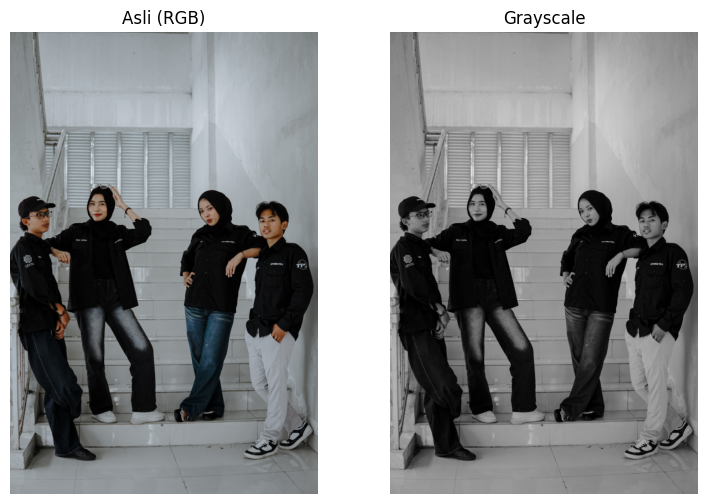

Contoh nilai piksel grayscale 3x3 (pojok kiri atas):
[[117 116 120]
 [119 120 120]
 [120 118 121]]


In [21]:
gray = to_grayscale(rgb)

fig, ax = plt.subplots(1, 2, figsize=(9, 6))
ax[0].imshow(rgb);  ax[0].set_title("Asli (RGB)")
ax[1].imshow(gray, cmap="gray", vmin=0, vmax=255); ax[1].set_title("Grayscale")
for a in ax: a.axis("off")
plt.show()

print("Contoh nilai piksel grayscale 3x3 (pojok kiri atas):")
print(gray[:3, :3])

## 5. Negatif
Membalik intensitas: area terang menjadi gelap dan sebaliknya.

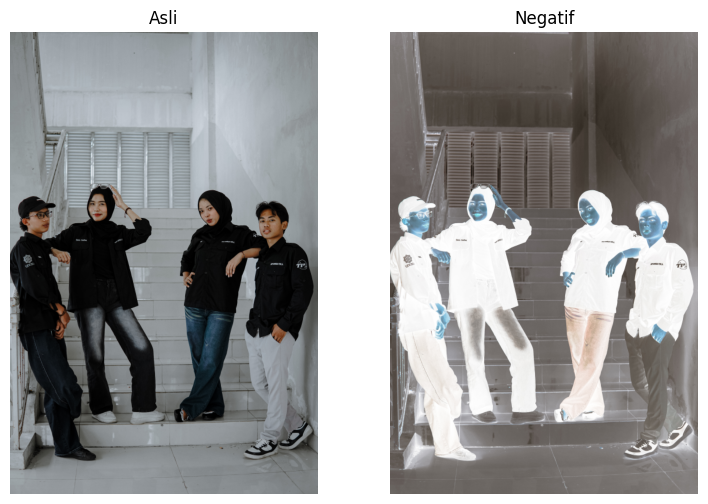

In [22]:
neg = negative(rgb)

fig, ax = plt.subplots(1, 2, figsize=(9, 6))
ax[0].imshow(rgb); ax[0].set_title("Asli")
ax[1].imshow(neg); ax[1].set_title("Negatif")
for a in ax: a.axis("off")
plt.show()

## 6. Brightness
Menambah konstanta ke setiap piksel. Nilai positif membuat citra lebih terang, nilai negatif lebih gelap.

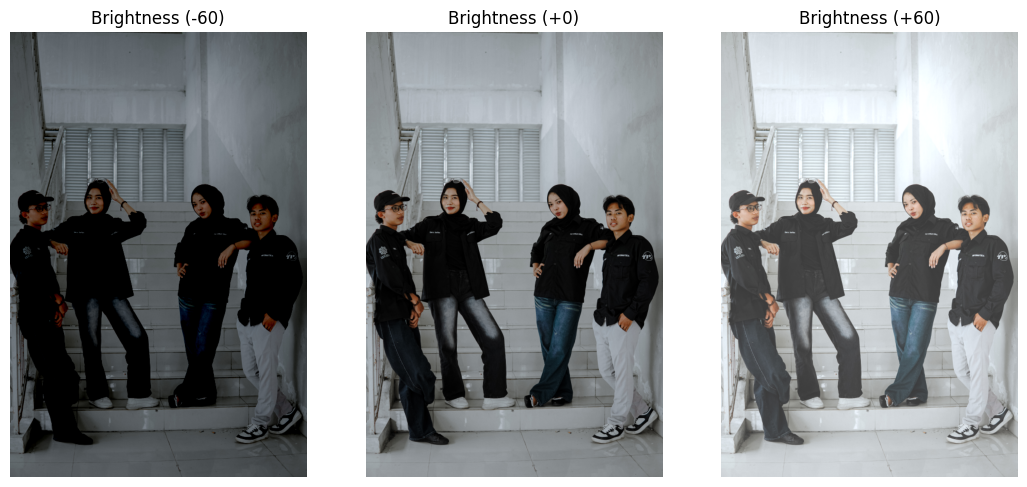

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(13, 6))
for a, beta in zip(ax, [-60, 0, 60]):
    a.imshow(brightness(rgb, beta))
    a.set_title(f"Brightness ({beta:+d})")
    a.axis("off")
plt.show()

## 7. Kontras
Meregangkan (c > 1) atau menyempitkan (c < 1) selisih intensitas terhadap titik tengah 128.

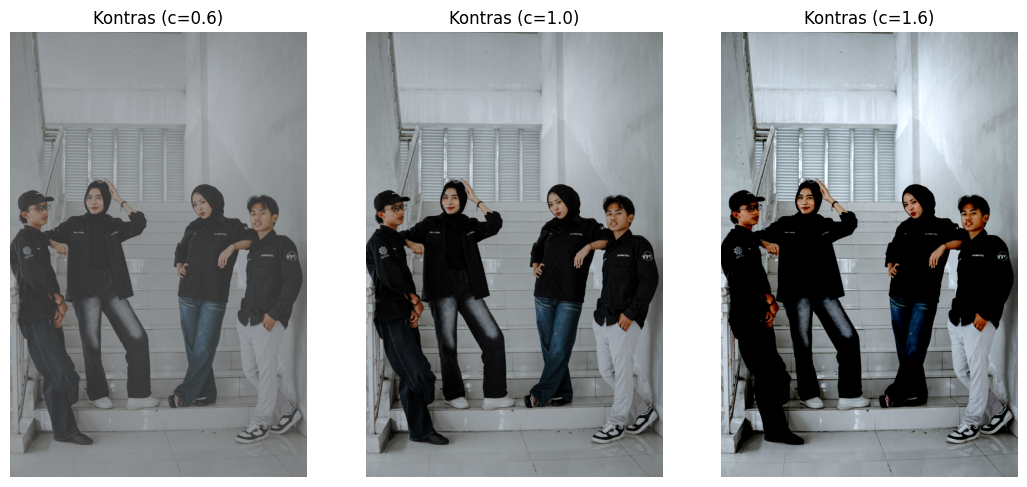

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(13, 6))
for a, c in zip(ax, [0.6, 1.0, 1.6]):
    a.imshow(contrast(rgb, c))
    a.set_title(f"Kontras (c={c})")
    a.axis("off")
plt.show()

## 8. Thresholding
Mengubah citra grayscale menjadi biner (hitam/putih) berdasarkan nilai ambang $T$.

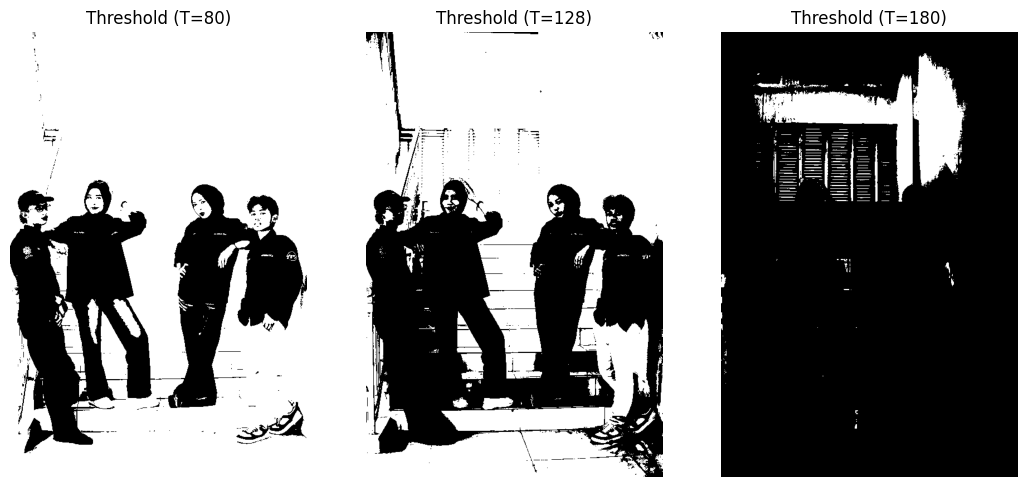

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(13, 6))
for a, t in zip(ax, [80, 128, 180]):
    a.imshow(threshold(gray, t), cmap="gray", vmin=0, vmax=255)
    a.set_title(f"Threshold (T={t})")
    a.axis("off")
plt.show()

## 9. Transformasi Log
Memperlebar rentang nilai gelap dan menekan rentang nilai terang, sehingga detail di area gelap lebih terlihat.

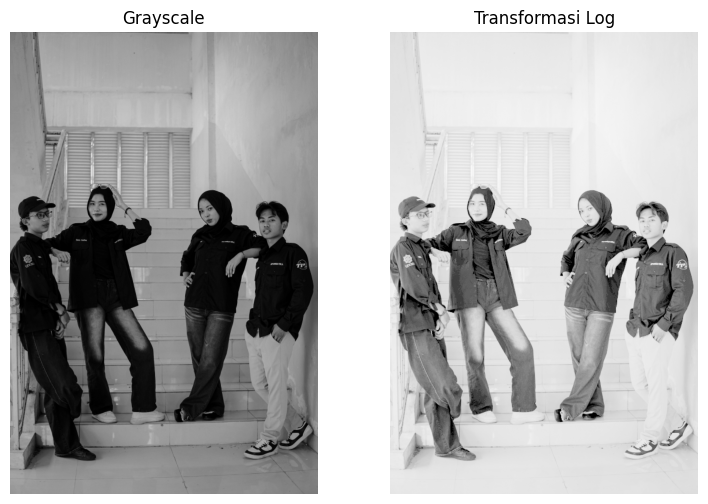

In [26]:
logimg = log_transform(gray)

fig, ax = plt.subplots(1, 2, figsize=(9, 6))
ax[0].imshow(gray, cmap="gray", vmin=0, vmax=255);   ax[0].set_title("Grayscale")
ax[1].imshow(logimg, cmap="gray", vmin=0, vmax=255); ax[1].set_title("Transformasi Log")
for a in ax: a.axis("off")
plt.show()

## 10. Gamma Correction
$\gamma < 1$ mencerahkan citra (detail gelap muncul), $\gamma > 1$ menggelapkan citra.

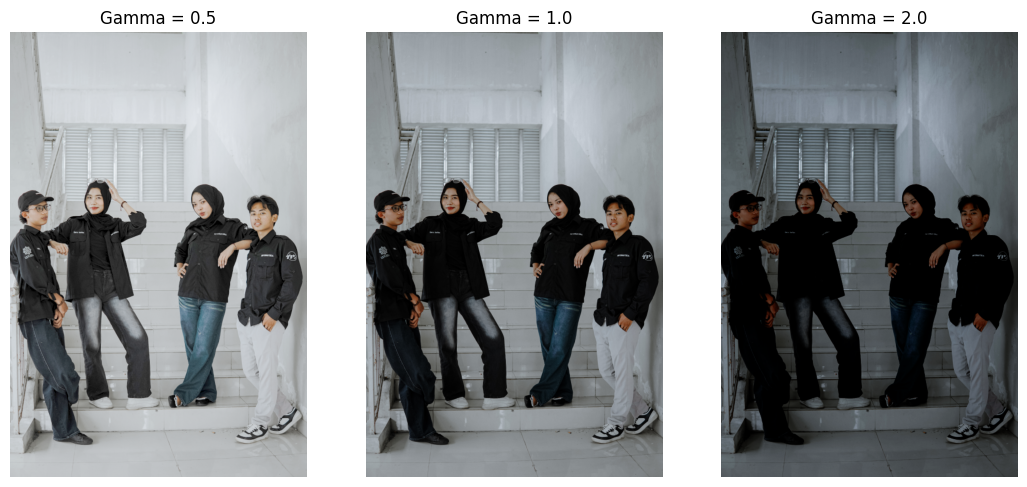

In [27]:
fig, ax = plt.subplots(1, 3, figsize=(13, 6))
for a, g in zip(ax, [0.5, 1.0, 2.0]):
    a.imshow(gamma_correction(rgb, g))
    a.set_title(f"Gamma = {g}")
    a.axis("off")
plt.show()

## 11. Perbandingan Semua Hasil

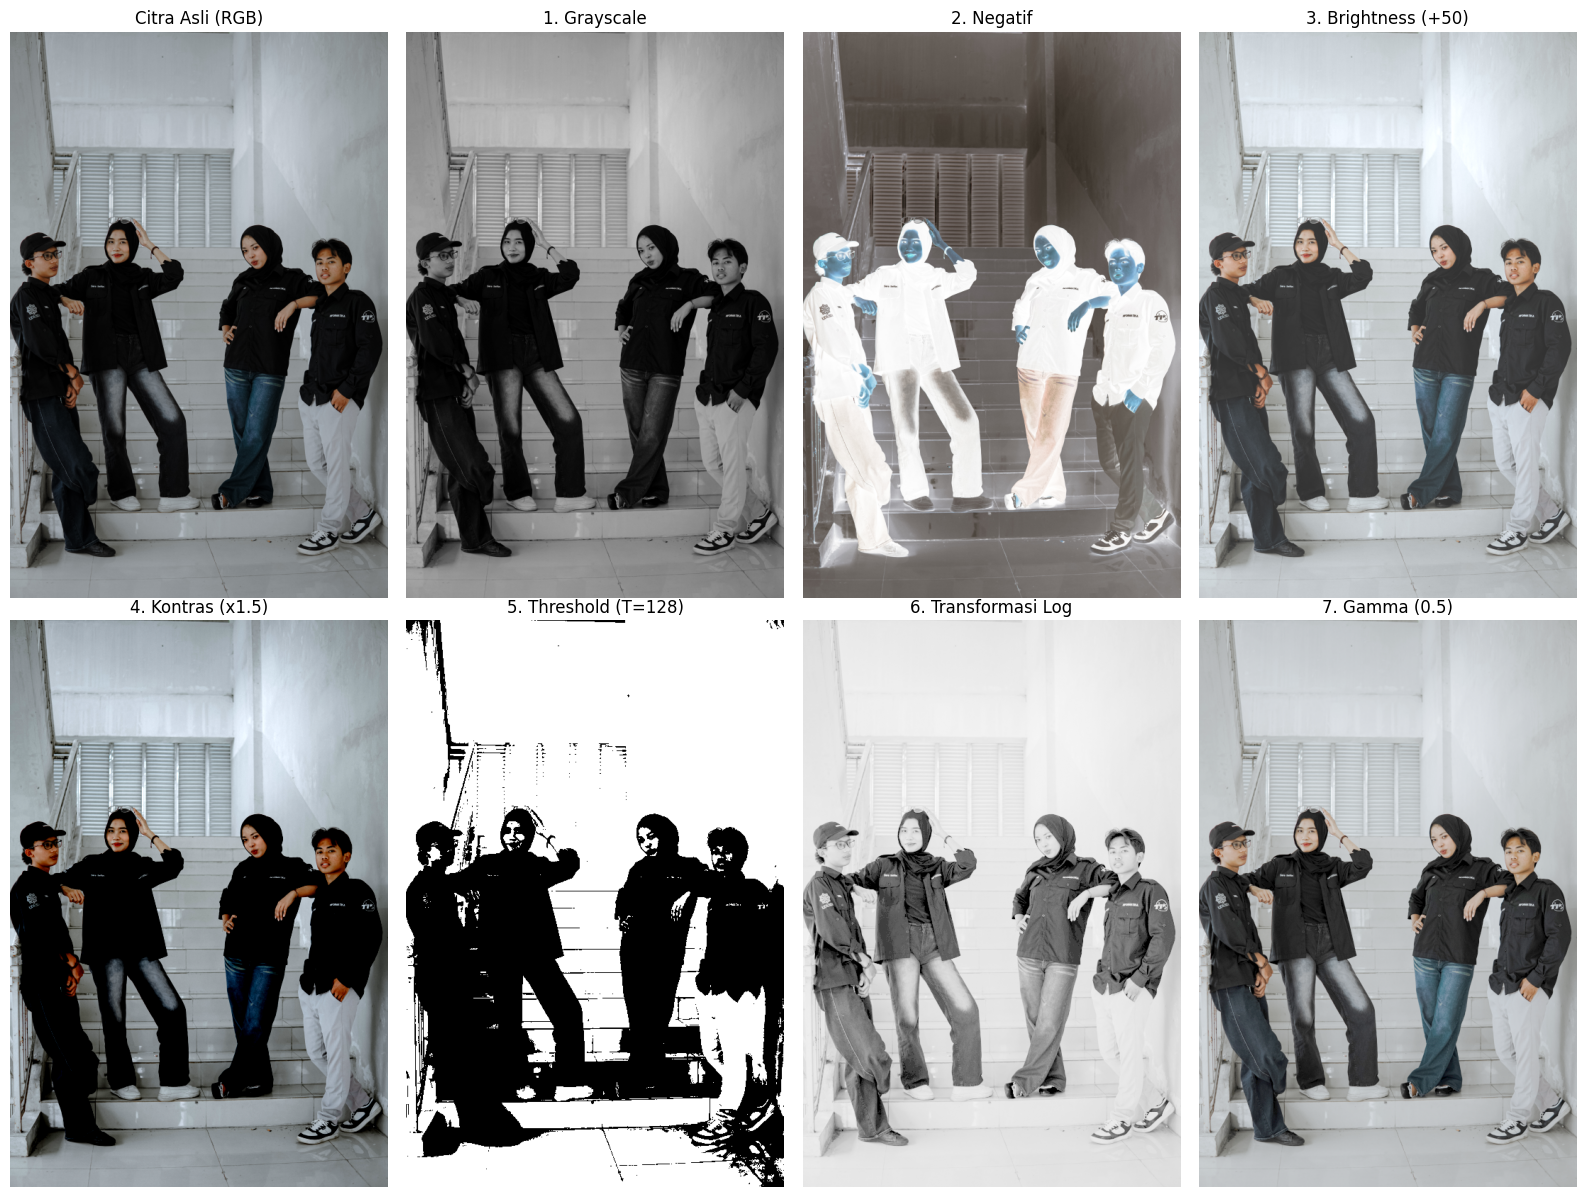

In [28]:
hasil = {
    "Citra Asli (RGB)": rgb,
    "1. Grayscale": gray,
    "2. Negatif": negative(rgb),
    "3. Brightness (+50)": brightness(rgb, 50),
    "4. Kontras (x1.5)": contrast(rgb, 1.5),
    "5. Threshold (T=128)": threshold(gray, 128),
    "6. Transformasi Log": log_transform(gray),
    "7. Gamma (0.5)": gamma_correction(rgb, 0.5),
}

fig, axes = plt.subplots(2, 4, figsize=(16, 12))
for ax, (judul, citra) in zip(axes.ravel(), hasil.items()):
    if citra.ndim == 2:
        ax.imshow(citra, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(citra)
    ax.set_title(judul)
    ax.axis("off")
plt.tight_layout()
plt.savefig("hasil_operasi_citra.png", dpi=120)
plt.show()

## 12. Histogram
Histogram menunjukkan sebaran nilai intensitas piksel sebelum dan sesudah operasi.

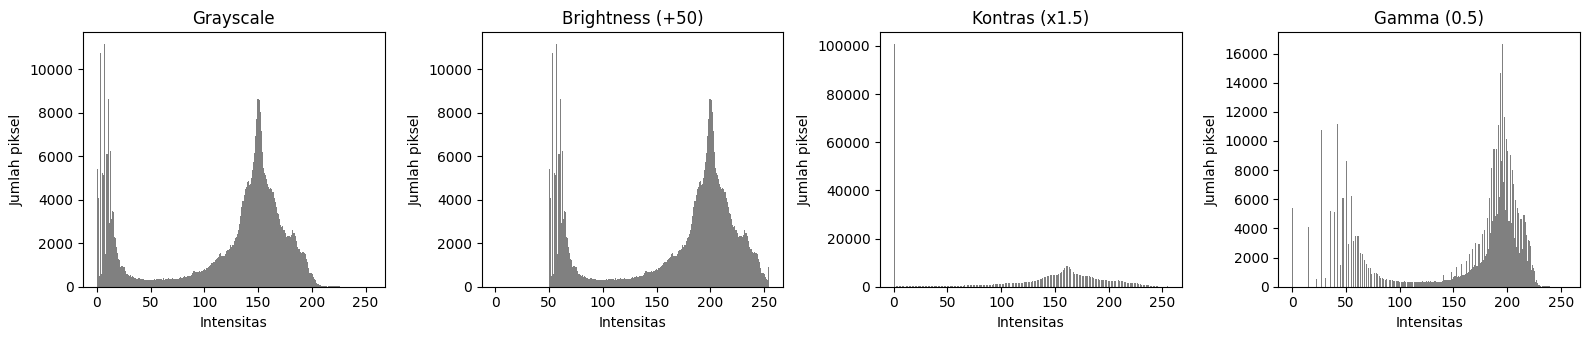

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, (judul, citra) in zip(axes, [
    ("Grayscale", gray),
    ("Brightness (+50)", brightness(gray, 50)),
    ("Kontras (x1.5)", contrast(gray, 1.5)),
    ("Gamma (0.5)", gamma_correction(gray, 0.5)),
]):
    ax.hist(citra.ravel(), bins=256, range=(0, 255), color="gray")
    ax.set_title(judul)
    ax.set_xlabel("Intensitas"); ax.set_ylabel("Jumlah piksel")
plt.tight_layout()
plt.show()

## 13. Kesimpulan
- Citra digital adalah susunan angka (matriks), sehingga setiap operasi dapat dilakukan dengan perhitungan pada nilai piksel.
- Point processing mengubah setiap piksel secara independen melalui fungsi $s = T(r)$.
- **Grayscale** menyederhanakan citra menjadi satu kanal; **negatif** membalik intensitas; **brightness** menggeser histogram; **kontras** melebarkan atau menyempitkan histogram.
- **Thresholding** menghasilkan citra biner; **transformasi log** dan **gamma** (γ < 1) memperjelas detail pada area gelap.